<a href="https://colab.research.google.com/github/Marcelujanocommits/ConnectaTel_An-lisis/blob/main/S7_Project_ConnectaTel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [ ]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [ ]:
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [ ]:
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [ ]:
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [ ]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [ ]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- Indica qué harías: ¿imputar, eliminar, ignorar?
- USERS:cuenta con valores nulos. En las columnas city 11% y churn_date 88%
- city: cuenta con un 11% de nulos por lo cual imputaría los datos
- churn_date: cuenta con 88% de nulos por lo cual ignorar esta columna es lo más propio
- USAGE: cuenta co valores nulos. En las columnas date 0.01%, duration 55% y length 44%
- date: cuenta con 0.01%. Por su bajo porcentaje se imputar la información.
- duration: cuenta con 55%. Porcentaje por el cual sería prioritario investigar antes de tomar una decisión sobre esta columna.
- length: cuenta con 44%. Mismo caso que duration, se investiga primero para decidir sobre la información de esta columna.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
- La columna `age` marca un valor en el min de -999 por lo cual debemos imputar la información ya que no es posible una edad en negativos

In [ ]:
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas duration 120 y length 1490 en max. En el caso de duration podemos considerar esto como un outlier ya que es posible realizar llamadas de duración prolongada sin embargo no es algo común. De igual forma en el caso de length se podría considerar como un posible Outlier ya que de igual forma se puede dar una situación en la cual se de un mensaje de texto con suficientes caracteres. Como mencion rápida mean 5 esta debajo de std 6 lo cual se ve ocasionado por los posibles outliers.

In [ ]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
users['city'].value_counts()
users['plan'].value_counts()


Basico     2595
Premium    1405
Name: plan, dtype: int64

- La columna `city` en el caso de esta columna tenemos datos aún por limpiar ya que los nombres se encuentran inconsistentes (mayusculas/minusculas) en su tipografía así como hay un sentinel "?" con un valor desconocido.
- La columna `plan` se encuentra limpia y sin inconsistencias

In [ ]:
# explorar columna categórica de usage
usage['type'].value_counts()

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` se encuentra limpia y uniforme sin necesidad de ningún tipo de cambio  


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels? En la columna "city", "churn_date"
- ¿Qué acción tomarías? dejar los nombres de las ciudades uniformes para tener datos bien organizados y visualmente agradables para su revisión y en el caso de los sentinels investigar si pertenecen a algún valor no reconocido para poder incluirlos en caso de ser posible

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')


In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'])

In [ ]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].min())
print(users['reg_date'].max())

2022-01-01 00:00:00
2026-05-10 00:00:00


En `reg_date`, esta columna no cuenta con datos a corregir o fuera delugar ya que tiene rangos de fechas razonables

In [ ]:
# Revisar los años presentes en `date` de usage
print(usage['date'].min())
print(usage['date'].max())

2024-01-01 00:00:00
2024-06-30 00:00:00


En `date`, el periodo que tenemos de seis meses es razonable y no se ven fechas invalidas o datos invalidos o fuera de tiempo en años muy atrás o fechas futuras.
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? No se encontraron en las columnas con fechas fechas que estuvieran muy lejanas o futuras tomando como referencia la fecha de hoy
- ¿Qué harías con ellas? En ese caso de haberlas tenido las hubiera sesgado o  investigado para poder validar la informacion e incluirla en el análisis

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age

age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, np.nan)
users['age'] = users['age'].fillna(age_mediana)


# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [ ]:

# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].describe()


count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [ ]:

# Marcar fechas futuras como NA para reg_date

hoy = pd.Timestamp.today()
futuras = users['reg_date'] > hoy
users['reg_date'] = users['reg_date'].astype(object)
users.loc[futuras,'reg_date'] = pd.NA


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).sum()

type
call        0
text    22076
Name: duration, dtype: int64

In [ ]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).sum()


type
call    17896
text        0
Name: length, dtype: int64


Las columnas duration (corresponde al 100% de los nulos en texto) y length (corresponde al 100% de nulos en call) tienen nulos esto es relacionado al hecho de que no es algo aleatorio si no una cuestión de estructura en los datos, cada columna se enfoca ya sea en la duración de la llamada o en el largo del texto (sms) por lo cual no tendría caso imputar la informacion ya que se complicaria el registro y organización de la misma, se dejan como nulos por lo tanto.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({'is_text': 'sum', 'is_call': 'sum', 'duration': 'sum'}).reset_index()


# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={'is_text':'cant_mensajes', 'is_call':'cant_llamadas', 'duration':'total_minutos_llamada'})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,total_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios

user_profile = pd.merge(users, usage_agg, on= 'user_id', how='left')
user_profile['total_messages'] = user_profile['cant_mensajes'].fillna(0)
user_profile['total_calls'] = user_profile['cant_llamadas'].fillna(0)
user_profile['total_duration'] = user_profile['total_minutos_llamada'].fillna(0)

user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,total_minutos_llamada,total_messages,total_calls,total_duration
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00,Basico,NaN,7.0,3.0,23.70,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [ ]:
# Resumen estadístico de las columnas numéricas
columnas_numericas = ["age", "cant_mensajes", "cant_llamadas", "total_minutos_llamada"]
resumen_numerico = user_profile[columnas_numericas].describe()
print(resumen_numerico)

               age  cant_mensajes  cant_llamadas  total_minutos_llamada
count  4000.000000    3999.000000    3999.000000            3999.000000
mean     48.136000       5.524381       4.478120              23.317054
std      17.689919       2.358416       2.144238              18.168095
min      18.000000       0.000000       0.000000               0.000000
25%      33.000000       4.000000       3.000000              11.120000
50%      48.000000       5.000000       4.000000              19.780000
75%      63.000000       7.000000       6.000000              31.415000
max      79.000000      17.000000      15.000000             155.690000


In [ ]:
# Distribución porcentual del tipo de plan
user_profile["plan"].value_counts(normalize=True)

Basico     0.64875
Premium    0.35125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

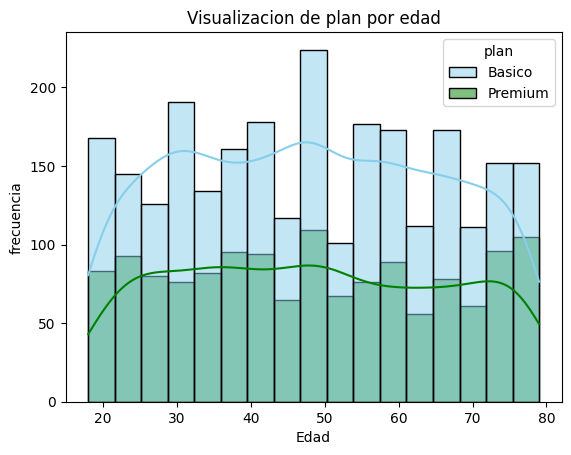

In [ ]:
# Histograma para visualizar la edad (age)

sns.histplot(data=user_profile, x='age', hue='plan' , palette=['skyblue','green'],  kde=True)
plt.title('Visualizacion de plan por edad')
plt.xlabel('Edad')
plt.ylabel('frecuencia')
plt.show()

💡Insights:
- El histograma se encuentra centrado (con un ligero sesgo a la derecha), de igual manera se puede ver de forma clara que el paquete basico es usado con una frecuencia del doble entre los usarios del rango de los 50 años, tambien se puede visibilizar que en edades debajo de los 50 esta tendencia se repite ya que casi el doble de los usuarios utiliza únicamente el plan básico lo cual cambia drásticamente en el caso de usuarios con 80 años que en su mayor frecuencia utilizan el plan premium.

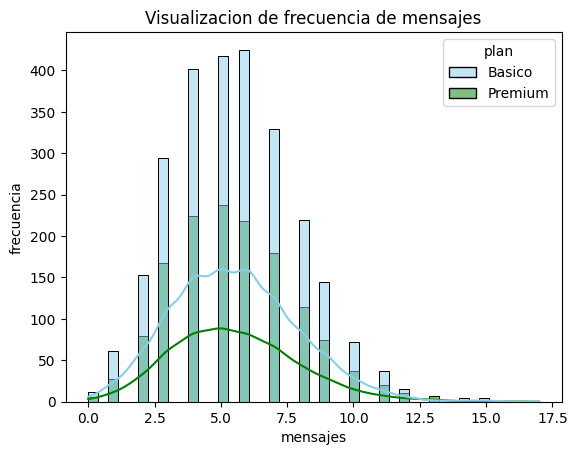

In [ ]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan' , palette=['skyblue','green'],  kde=True)
plt.title('Visualizacion de frecuencia de mensajes')
plt.xlabel('mensajes')
plt.ylabel('frecuencia')
plt.show()

💡Insights:
- En el histograma se ve claramente con sesgo a la derecha, complementando esto podemos observar la significativa frecuencia con la que los clientes del plan básico mandan mensajes, algunas veces duplicando la frecuencia y cantidad de aquellos que tienen el plan premium

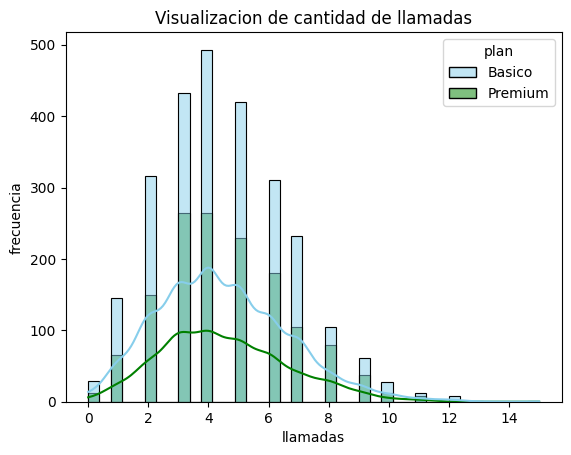

In [ ]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan' , palette=['skyblue','green'],  kde=True)
plt.title('Visualizacion de cantidad de llamadas')
plt.xlabel('llamadas')
plt.ylabel('frecuencia')
plt.show()

💡Insights:
- En este histograma, tenemos sesgo a la derecha y las barras y la curva del plan básico tienen frecuencias más altas que aquella que pertenece al plan premium en la mayoria de las barras.Por lo cual podemos dar por el entendido de que los clientes que cuentan con plan basico realizan llamadas con mas frecuencia que aquellos de plan premium.

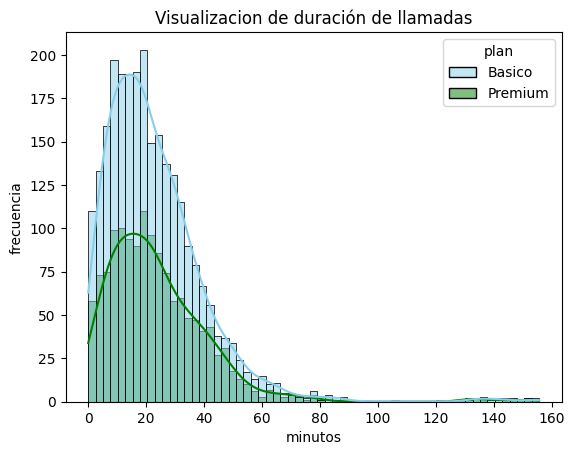

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='total_minutos_llamada', hue='plan' , palette=['skyblue','green'],  kde=True)
plt.title('Visualizacion de duración de llamadas')
plt.xlabel('minutos')
plt.ylabel('frecuencia')
plt.show()

💡Insights:
- Este histograma es claramente sesgado a la derecha y nos muestra una vez más el como los clientes de plan básico son los que suelen ser más activos en su actividad en cuanto a su plan. Siendo más específicos en este caso podemos ver como los del plan básico duplican prácticamente todas las barra de minutos comparado con los de plan premium.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.



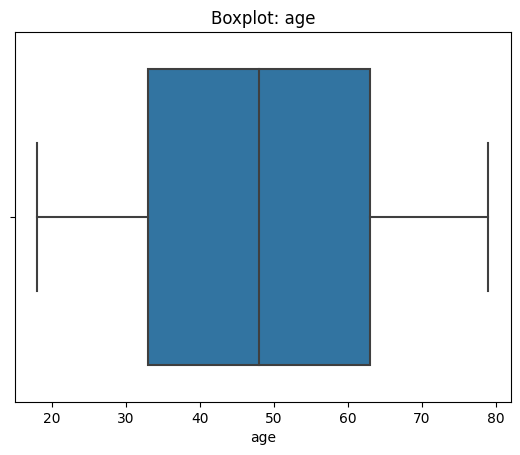

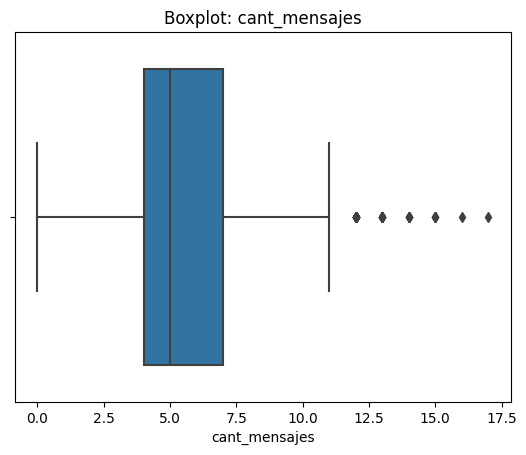

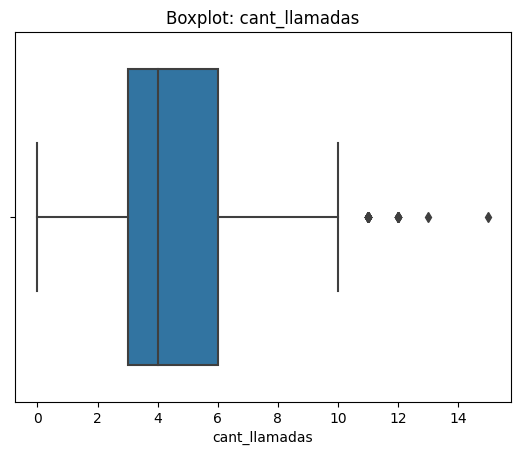

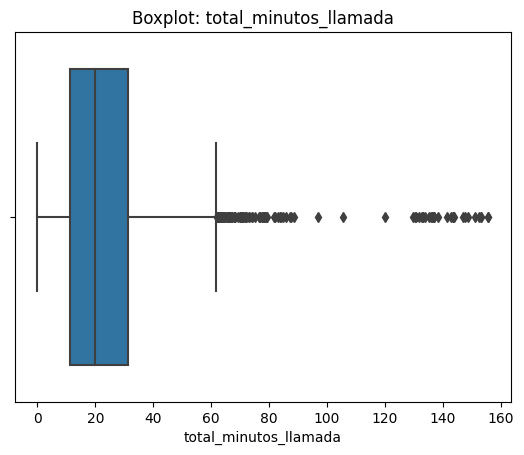

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'total_minutos_llamada']



for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.show()



💡Insights:


- Age: ... No presenta outliers
- cant_mensajes: Presenta outliers
- cant_llamadas: Presenta outliers
- cant_minutos_llamada: Presenta una cantidad considerable de outliers



In [ ]:
# Calcular límites con el método IQR

columnas_limites = ['cant_mensajes', 'cant_llamadas', 'total_minutos_llamada']
for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    outliers = user_profile[(user_profile[col] < limite_inferior) | (user_profile[col] > limite_superior)]
    print(col)
    print(outliers)


cant_mensajes
      user_id first_name last_name   age      city  \
315     10315     Carlos     Lopez  30.0       MTY   
347     10347     Carlos    Garcia  77.0      Cali   
356     10356      Mateo    Garcia  42.0      CDMX   
384     10384      Sofia   Ramirez  35.0      CDMX   
456     10456      Mateo   Ramirez  48.0      CDMX   
539     10539      Sofia   Ramirez  77.0      Cali   
591     10591        Ana     Gomez  25.0       NaN   
670     10670     Carlos    Torres  47.0    Bogotá   
903     10903     Carlos     Lopez  63.0      CDMX   
908     10908    Mariana     Lopez  56.0       MTY   
987     10987      Mateo   Ramirez  30.0       GDL   
1054    11054      Mateo     Lopez  72.0      Cali   
1159    11159    Mariana    Torres  79.0    Bogotá   
1173    11173      Sofia    Torres  37.0    Bogotá   
1197    11197     Carlos    Torres  48.0       GDL   
1255    11255      Sofia     Lopez  71.0       NaN   
1282    11282      Mateo     Gomez  72.0  Medellín   
1816    11816 

In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,total_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights:
- cant_mensajes: tenemos 45 filass de outliers y a pesar de que estto cae en un rango de lo que se puede contar puede ser un poco tedioso a la hora de hacerlo para poder tener esta informacion presente en nuestro analisis de datos. Se mantenienen los datos ya que son outliers.
- cant_llamadas: mantener o no outliers: Tenemos 30 filas de outliers mismo caso que en cant_mensajes son cantidades con las cuales hay que ir con pinzas pero son posibles. Por el mismo criterio se mantienen en el analisis.
- cant_minutos_llamada: mantener o no outliers: Esta es la columna que cuenta con valores mas allejados del promedio o la media ya que van de 70 hasta 150 aproximadamente lo cual dispara muchisimo el rango de outliers en nuestra sandbox yo dejaria estos valores ya que representan comportamiento de clientes de alto consumo a pesar de afectar nuestros valores promedios.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
# Crear columna grupo_uso

def clasificar_uso(row):
    if row['cant_llamadas'] < 5 and row['cant_mensajes'] < 5:
        return "Bajo uso"
    elif row['cant_llamadas'] < 10 and row['cant_mensajes'] < 10:
        return "Uso medio"
    else:
        return 'Alto uso'

user_profile["grupo_uso"] = user_profile.apply(clasificar_uso, axis=1)
print(user_profile['grupo_uso'].value_counts())


Uso medio    2943
Bajo uso      778
Alto uso      279
Name: grupo_uso, dtype: int64


In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,total_minutos_llamada,total_messages,total_calls,total_duration,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00,Basico,NaN,7.0,3.0,23.70,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,4.0,3.0,8.01,Bajo uso


In [ ]:
# Crear columna grupo_edad
def clasificar_edad(row):
    if row['age'] < 30:
        return "Joven"
    elif row['age'] < 60:
        return "Adulto"
    else:
        return 'Adulto Mayor'

user_profile["grupo_edad"] = user_profile.apply(clasificar_edad, axis=1)
print(user_profile['grupo_edad'].value_counts())

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64


In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,total_minutos_llamada,total_messages,total_calls,total_duration,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00,Basico,NaN,7.0,3.0,23.70,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

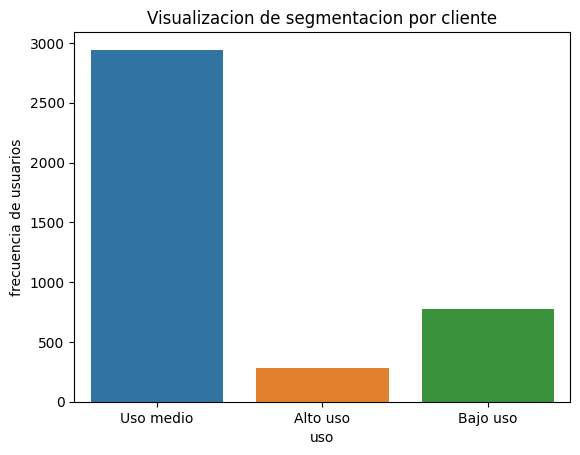

In [ ]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso')
plt.title('Visualizacion de segmentacion por cliente')
plt.xlabel('uso')
plt.ylabel('frecuencia de usuarios')

plt.show()


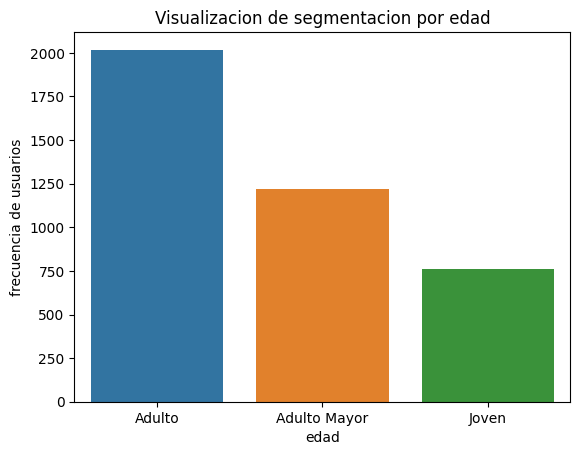

In [ ]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad')
plt.title('Visualizacion de segmentacion por edad')
plt.xlabel('edad')
plt.ylabel('frecuencia de usuarios')

plt.show()

In [ ]:

pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'])

grupo_uso,Alto uso,Bajo uso,Uso medio
grupo_edad,,,
Adulto,154,364,1500
Adulto Mayor,74,257,891
Joven,51,157,552


## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
Las primeras tablas tenían valores nulos así como typeos en la escritura. Se corrigieron valores nulos, se corrigieron formatos de fecha y se detectaron valores considerados como sentinels. En users teníamos 11% dee valores nulos en city y en chun_date contaba con 88% de nulos, en este caso tuvimos que descartar usar esta tabla ya que imputarla hubiera complicado el tratamiento de los ddmas datos por su alto porcentaje. En el caso dd usage se tenia en duration un 55% y en lentgh un 44%. En los casos de 'city', 'duration' y 'length' por su bajo porcentaje fueron imputados

- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?
En el caso de adultos vemos que tienen un uso constante y nos desglosa que a pesar de tener una cantidad de adultos mayores alta no significa que sean los usuarios que mas utilicen el servicio. De igual manera es importante recalcar que no hay un grupo de edad que mas utilice el servicio ya que están parejos en porcentajes de uso quedando de la siguiente forma los adultos con un 74%. En los casos de adulto mayor utilizan el servicio con 891 de 1222 representado por un 73% y por último los jovenes quienes tienen un uso con 552 de 760 representado por el 73%
  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?
Basándome en los porcentajes diría que todos los sectores tienen un nivel alto de importancia por los porcentajes en uso que tienen. Sin embargo en cantidades el grupo de adulto seria el más valioso por cantidad de consumidores

- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?
En el caso de outliers en duration y length ya que hablamos de llamadas peculiarmtente largas y de mensajes largos considero que es valioso para la compañía ya que pudiera ser un signo de clientesvde alto consumo. Por lo cual se podría considerar que entren en un rango de "clientes VIP" y poder ofrecer planes más caros con mayores beneficios

- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?
Ofrecer beneficios o promociones para que los clientes de cualquier edad o sector comenzarán a incrementar su consumo y con base en eso hacer un aumento progresivo en los panes a cambio de dar mayores beneficios. Esto enfocándose en En los niveles de uso de los clientes y en el caso especifico de los "VIP" recomendaria darle beneficios no únicamente de mayores beneficios para llamadas o mensajes también daría beneficios como descuentos por pronto pago o descuentos en la contratación de planes para líneas extras o adquisición de equipos en caso de vender equipos celulares también

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

- Durante la exploración inicial se identificaron inconsistencias en la calidad de los datos, principalmente valores nulos, errores tipográficos, formatos de fecha inconsistentes y valores sentinels (valores utilizados para representar información faltante o no válida).

- En la tabla users, la columna city presentaba un 11% de valores nulos, mientras que churn_date registraba un 88%. Debido al alto porcentaje de ausencia de información en esta última columna, se determinó descartar su utilización para evitar imputaciones poco confiables que pudieran comprometer la calidad del análisis.

- En la tabla usage, se identificaron valores faltantes en las columnas duration (55%) y length (44%). Para las variables city, duration y length, se aplicaron procesos de imputación, considerando que era viable recuperar la información sin comprometer significativamente el análisis.

- Finalmente, se estandarizaron los formatos de fecha, se corrigieron inconsistencias de escritura y se trataron los valores atípicos identificados, con el objetivo de garantizar una mayor consistencia y confiabilidad en los resultados.


🔍 **Segmentos por Edad**

- El análisis permitió identificar tres segmentos principales: jóvenes, adultos y adultos mayores. Los resultados muestran que no existe una diferencia significativa en el porcentaje de uso entre los grupos, ya que todos mantienen niveles de utilización similares.

- Los adultos presentan un porcentaje de uso del 74%, posicionándose como el segmento con mayor participación. Además, representan el grupo más numeroso en términos de consumidores.

- Los adultos mayores registran 891 usuarios activos de un total de 1,222, lo que representa aproximadamente un 73% de utilización.

- Por su parte, los jóvenes presentan 552 usuarios activos de un total de 760, equivalente a un 73% de utilización.

- Estos resultados demuestran que la edad no representa un factor determinante para el uso del servicio, ya que los tres segmentos mantienen porcentajes de participación prácticamente equivalentes.

📊 **Segmentos por Nivel de Uso**

-Se identificó un comportamiento de consumo relativamente equilibrado entre los distintos grupos de edad, con porcentajes de utilización que oscilan entre el 73% y el 74%.

- Aunque los adultos mayores representan una cantidad considerable de usuarios, esto no significa necesariamente que sean quienes generan el mayor consumo del servicio.

- En términos de volumen de clientes, el segmento de adultos representa la mayor oportunidad comercial para ConnectaTel, debido a que concentra una mayor cantidad de consumidores.

- Adicionalmente, se identificaron valores atípicos (outliers) en las variables duration y length, correspondientes a llamadas de duración inusualmente prolongada y mensajes considerablemente extensos. Estos comportamientos podrían representar usuarios con patrones de consumo elevado y, por lo tanto, una oportunidad para desarrollar estrategias de fidelización y monetización.

➡️ Esto sugiere que...

- ConnectaTel cuenta con una base de clientes diversificada en la que los distintos grupos de edad presentan niveles de utilización muy similares. Por lo tanto, las estrategias comerciales no deberían enfocarse exclusivamente en un rango de edad, sino principalmente en los hábitos y niveles de consumo de cada usuario.

- El segmento de adultos representa la mayor oportunidad en términos de volumen de clientes; sin embargo, los usuarios que presentan patrones de consumo extraordinarios también podrían representar un segmento de alto valor comercial.

- Asimismo, los valores atípicos identificados en llamadas y mensajes podrían utilizarse como punto de partida para identificar potenciales clientes VIP, siempre que se valide que estos patrones corresponden a un comportamiento recurrente y no a registros aislados o inconsistencias en los datos.


💡 **Recomendaciones**
-
- Implementar estrategias de incremento de consumo: desarrollar promociones y beneficios dirigidos a todos los grupos de edad, incentivando un mayor uso de los servicios de llamadas y mensajes.

- Desarrollar planes escalonados: implementar una estrategia de crecimiento progresivo en la oferta de planes, permitiendo que los clientes migren a opciones de mayor costo a cambio de beneficios adicionales de acuerdo con sus necesidades y niveles de consumo.

- Aprovechar el segmento de adultos: al representar el mayor volumen de consumidores, se recomienda diseñar campañas comerciales específicas para este grupo, buscando incrementar su consumo y fortalecer su fidelización.

- Crear un segmento de clientes VIP: identificar a los usuarios con patrones de consumo elevados y recurrentes para ofrecerles planes premium con mayores beneficios en llamadas y mensajes.

- Ofrecer beneficios adicionales a clientes de alto valor: complementar los planes VIP con incentivos como descuentos por pronto pago, promociones en la contratación de líneas adicionales y descuentos en la adquisición de equipos celulares, en caso de que ConnectaTel comercialice estos productos.

- Monitorear el comportamiento de los usuarios: establecer indicadores de seguimiento que permitan evaluar la evolución del consumo, la efectividad de las promociones y la migración de clientes hacia planes de mayor valor.